# Entrega Matemática IV - 2026 Conjunto B

## Dataset

Cada fila es un día de operación del sistema público de bicicletas de Washington D.C. durante 2011 y 2012, con las
condiciones meteorológicas de ese día y la cantidad total de alquileres. El operador quiere anticipar la demanda para
dimensionar la flota.

In [ ]:
!curl -fsLO https://raw.githubusercontent.com/danwild/bike-share-prediction/master/Bike-Sharing-Dataset/day.csv

In [ ]:
import pandas as pd

data = pd.read_csv('/content/day.csv')
data.head(5)

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## Definiciones

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import t
from numpy.typing import ArrayLike

class RegresionSimple:
    def __init__(self, variable: str, x: ArrayLike, y: ArrayLike):
        self.variable = variable
        self.x, self.y = x, y

        self.sxx = np.sum((x - x.mean()) ** 2)
        self.sxy = np.sum((x - x.mean()) * (y - y.mean()))
        self.syy = np.sum((y - y.mean()) ** 2)

        # Estimadores
        self.beta1 = self.sxy / self.sxx
        self.beta0 = y.mean() - self.beta1 * x.mean()

        # Variabilidad
        self.sce = np.sum((y - self(x)) ** 2)
        self.scr = np.sum((self(x) - y.mean()) ** 2)
        self.stc = self.scr + self.sce
        self.r2 = 1 - self.sce / self.stc
        self.r = np.sqrt(self.r2) * np.sign(self.beta1)
        self.sigma2 = self.sce / (len(x) - 2)

    def __call__(self, x):
        return self.beta1 * x + self.beta0

    def __len__(self) -> int:
        return len(self.y)

    def ic_beta1(self, alpha=0.05):
        n = len(self)
        std = np.sqrt(self.sigma2 / self.sxx)
        return t.interval(1-alpha/2, df=n-2, loc=self.beta1, scale=std)

    def ic_beta0(self, alpha=0.05):
        n = len(self)
        std = np.sqrt(self.sigma2 * (1/n + self.x.mean()**2/self.sxx))
        return t.interval(1-alpha, df=n-2, loc=self.beta0, scale=std)

    def ic_media(self, x_estrella, alpha=0.05):
        n = len(self)
        std = np.sqrt(self.sigma2 * (1/n + (x_estrella - self.x.mean())**2 / self.sxx))
        return t.interval(1-alpha, df=n-2, loc=self(x_estrella), scale=std)

    def ic_prediccion(self, x_estrella, alpha=0.05):
        n = len(self)
        std = np.sqrt(self.sigma2 * (1 + 1/n + (x_estrella - self.x.mean())**2 / self.sxx))
        return t.interval(1-alpha, df=n-2, loc=self(x_estrella), scale=std)


def tabular_modelos(modelos, x_estrella=0.65):
    # Generado por Claude y modificado

    def fmt_ic(ic):
        return f"[{ic[0]:.4f}, {ic[1]:.4f}]"

    filas = []

    for modelo in modelos:
        filas.append({
            'variable': modelo.variable,
            'beta1': modelo.beta1,
            'beta0': modelo.beta0,
            'sigma2': modelo.sigma2,
            'r2': modelo.r2,
            'r': modelo.r,
            'IC(beta1)': fmt_ic(modelo.ic_beta1()),
            'IC(beta0)': fmt_ic(modelo.ic_beta0()),
            f'IC media(Y|x*={x_estrella})': fmt_ic(modelo.ic_media(x_estrella)),
            f'IC predicción(Y|x*={x_estrella})': fmt_ic(modelo.ic_prediccion(x_estrella)),
        })

    return pd.DataFrame(filas).set_index('variable')


def graficar_modelo(modelo, nombre_x='x', nombre_y='y'):
    x = np.asarray(modelo.x)
    y = np.asarray(modelo.y)

    # Rango continuo para dibujar la recta
    x_linea = np.linspace(x.min(), x.max(), 200)
    y_linea = modelo(x_linea)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(x, y, alpha=0.5, s=15, label='Observado')
    ax.plot(x_linea, y_linea, color='red', linewidth=2, label='Recta de regresión estimada')

    ax.set_xlabel(nombre_x)
    ax.set_ylabel(nombre_y)
    ax.set_title(f'Regresión simple: {nombre_y} vs {nombre_x}')
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.show()

## Parte A — Complementos de Análisis Matemático

### A.1 - Derivación y modelo cuadrático

1. MODELO CUADRÁTICO AJUSTADO:
   ŷ(x) = -1901.9557 + (21406.9313)·x + (-15055.0254)·x²

2. EVALUACIÓN DE LA DERIVADA EN DOS PUNTOS:
   Para x = 0.20 (8.2 °C):
     dŷ/dx = 15384.92 bicicletas / unidad norm.
     Tasa física = 375.24 bicicletas / °C

   Para x = 0.70 (28.7 °C):
     dŷ/dx = 329.90 bicicletas / unidad norm.
     Tasa física = 8.05 bicicletas / °C

3. ANÁLISIS DEL PUNTO CRÍTICO:
   Punto crítico: x* = 0.7110 (~29.15 °C)
   Derivada segunda d²ŷ/dx² = -30110.05
   -> Al ser d²ŷ/dx² < 0, se confirma que es un MÁXIMO local.
   Rango observado de temp: [0.0591, 0.8617] (~[2.4 °C, 35.3 °C])
   -> El punto crítico CAE dentro del rango observado.

VARIABILIDAD
r2=0.45317902549082945


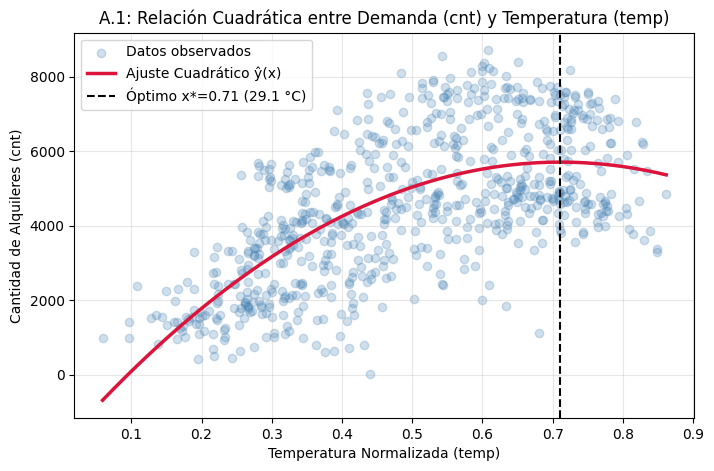

In [ ]:


# ==========================================
# SECCIÓN A.1: DERIVACIÓN Y MODELO CUADRÁTICO
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
##cargamos data
url = "https://raw.githubusercontent.com/danwild/bike-share-prediction/master/Bike-Sharing-Dataset/day.csv"
data = pd.read_csv(url)

# 1. Ajuste polinómico cuadrático (grado 2)
# np.polyfit devuelve los coeficientes en orden decreciente: [beta2, beta1, beta0]
beta2, beta1, beta0 = np.polyfit(data['temp'], data['cnt'], 2)

print("1. MODELO CUADRÁTICO AJUSTADO:")
print(f"   ŷ(x) = {beta0:.4f} + ({beta1:.4f})·x + ({beta2:.4f})·x²\n")

def f(x):
    return beta0 + beta1*x + beta2*x**2

# 2. Definición de la derivada primera dŷ/dx = beta1 + 2*beta2*x
def dy_dx(x):
    return beta1 + 2 * beta2 * x

# Puntos representativos para evaluar: x = 0.20 (~8.2 °C) y x = 0.70 (~28.7 °C)
x_puntos = [0.20, 0.70]
print("2. EVALUACIÓN DE LA DERIVADA EN DOS PUNTOS:")
for x_val in x_puntos:
    t_celsius = x_val * 41.0
    deriv_norm = dy_dx(x_val)
    # Como temp_celsius = x * 41, por regla de la cadena dŷ/d(°C) = (dŷ/dx) / 41
    deriv_celsius = deriv_norm / 41.0
    print(f"   Para x = {x_val:.2f} ({t_celsius:.1f} °C):")
    print(f"     dŷ/dx = {deriv_norm:.2f} bicicletas / unidad norm.")
    print(f"     Tasa física = {deriv_celsius:.2f} bicicletas / °C\n")

# 3. Punto crítico: dŷ/dx = 0  =>  x* = -beta1 / (2*beta2)
x_critico = -beta1 / (2 * beta2)
temp_opt_c = x_critico * 41.0
deriv2 = 2 * beta2  # Derivada segunda constante

print("3. ANÁLISIS DEL PUNTO CRÍTICO:")
print(f"   Punto crítico: x* = {x_critico:.4f} (~{temp_opt_c:.2f} °C)")
print(f"   Derivada segunda d²ŷ/dx² = {deriv2:.2f}")
if deriv2 < 0:
    print("   -> Al ser d²ŷ/dx² < 0, se confirma que es un MÁXIMO local.")

rango_min, rango_max = data['temp'].min(), data['temp'].max()
print(f"   Rango observado de temp: [{rango_min:.4f}, {rango_max:.4f}] (~[{rango_min*41:.1f} °C, {rango_max*41:.1f} °C])")
if rango_min <= x_critico <= rango_max:
    print("   -> El punto crítico CAE dentro del rango observado.\n")

mean = data['cnt'].mean()

sce = np.sum((data['cnt'] - f(data['temp'])) ** 2)
scr = np.sum((f(data['temp']) - data['cnt'].mean()) ** 2)
stc = sce + scr

print(f"VARIABILIDAD")
print(f"r2={1 - sce / stc}")

# 4. Gráfico del ajuste cuadrático
plt.figure(figsize=(8, 5))
plt.scatter(data['temp'], data['cnt'], alpha=0.25, color='steelblue', label='Datos observados')
x_grid = np.linspace(rango_min, rango_max, 250)
y_pred_quad = np.polyval([beta2, beta1, beta0], x_grid)
plt.plot(x_grid, y_pred_quad, color='crimson', lw=2.5, label='Ajuste Cuadrático ŷ(x)')
plt.axvline(x_critico, color='black', linestyle='--', label=f'Óptimo x*={x_critico:.2f} ({temp_opt_c:.1f} °C)')
plt.xlabel('Temperatura Normalizada (temp)')
plt.ylabel('Cantidad de Alquileres (cnt)')
plt.title('A.1: Relación Cuadrática entre Demanda (cnt) y Temperatura (temp)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


#### Notas de interpretación

* La comparación de valores de la derivada muestra que la demanda de bicicletas crece más lentamente conforme aumenta la temperatura

* La derivada del modelo lineal no es otra que su pendiente; esto supone que la demanda de bicicletas aumenta en forma constante

* El punto crítico hallado se encuentra dentro del rango observado y es un máximo (f''(x) < 0 -> f es cóncava). Sugiere que cuando la temperatura es superior a ~29.15ºC, hace demasiado calor para andar en bicicleta y la demanda se da vuelta


### A.2 - Derivadas parciales y ecuaciones normales

TODO: Hay que hacer el paso a paso de la derivación

          RESULTADOS SECCIÓN A.2: REGRESIÓN SIMPLE         
Número de observaciones (n): 731
Media de temp (x̄): 0.4954
Media de cnt  (ȳ): 4504.3488
Sxy = 162435.7313
Sxx = 24.4606

--- Fórmulas Analíticas (Sxy / Sxx) ---
  β̂₁ (pendiente)          = 6640.709999
  β̂₀ (ordenada al origen) = 1214.642119

--- Librería Estándar (np.polyfit) ---
  β̂₁ = 6640.709999
  β̂₀ = 1214.642119

✔ VERIFICACIÓN EXITOSA: Ambos métodos coinciden exactamente.
✔ Coincide de forma unívoca con la fila 'temp' de la Parte B.2 de tu compañero:
    β̂₁ = 6640.71  |  β̂₀ = 1214.64

-----------------------------------------------------------
RECTA OBTENIDA:  ŷ = 1214.64 + 6640.71 · x
-----------------------------------------------------------


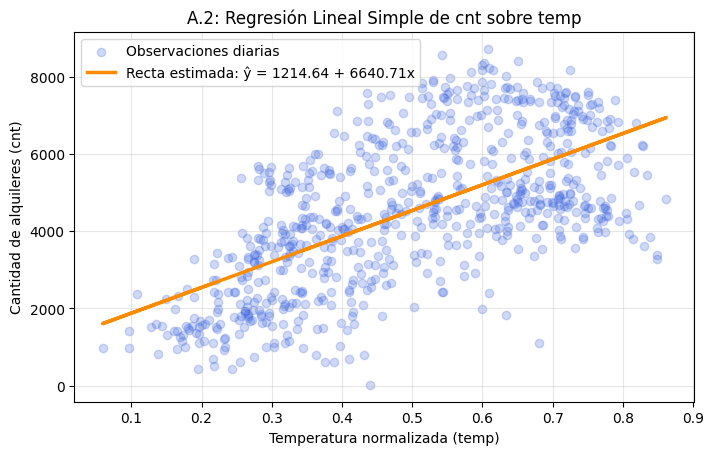

In [ ]:
## A.2 - Derivadas parciales y ecuaciones normales

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Carga de seguridad de datos por si no se ejecutaron celdas previas
if 'data' not in globals():
    url = "https://raw.githubusercontent.com/danwild/bike-share-prediction/master/Bike-Sharing-Dataset/day.csv"
    data = pd.read_csv(url)

# Variables: x = temperatura normalizada, y = cantidad de alquileres
x = data['temp'].values
y = data['cnt'].values
n = len(x)

# 1. Cálculo de las sumatorias fundamentales
sum_x  = np.sum(x)
sum_y  = np.sum(y)
sum_xy = np.sum(x * y)
sum_xx = np.sum(x**2)

x_bar = sum_x / n
y_bar = sum_y / n

# 2. Cálculo manual de Sxy y Sxx
Sxy = sum_xy - (sum_x * sum_y) / n
Sxx = sum_xx - (sum_x**2) / n

# 3. Estimadores de mínimos cuadrados por fórmula analítica
beta1_manual = Sxy / Sxx
beta0_manual = y_bar - beta1_manual * x_bar

# 4. Ajuste mediante librería (np.polyfit grado 1 / regresión lineal)
poly_ajuste = np.polyfit(x, y, 1)
beta1_lib = poly_ajuste[0]
beta0_lib = poly_ajuste[1]

# 5. Salida por consola
print("===========================================================")
print("          RESULTADOS SECCIÓN A.2: REGRESIÓN SIMPLE         ")
print("===========================================================")
print(f"Número de observaciones (n): {n}")
print(f"Media de temp (x̄): {x_bar:.4f}")
print(f"Media de cnt  (ȳ): {y_bar:.4f}")
print(f"Sxy = {Sxy:.4f}")
print(f"Sxx = {Sxx:.4f}\n")

print(f"--- Fórmulas Analíticas (Sxy / Sxx) ---")
print(f"  β̂₁ (pendiente)          = {beta1_manual:.6f}")
print(f"  β̂₀ (ordenada al origen) = {beta0_manual:.6f}\n")

print(f"--- Librería Estándar (np.polyfit) ---")
print(f"  β̂₁ = {beta1_lib:.6f}")
print(f"  β̂₀ = {beta0_lib:.6f}\n")

# Comprobación de consistencia
diferencia = abs(beta1_manual - beta1_lib) + abs(beta0_manual - beta0_lib)
if diferencia < 1e-6:
    print("✔ VERIFICACIÓN EXITOSA: Ambos métodos coinciden exactamente.")
    print("✔ Coincide de forma unívoca con la fila 'temp' de la Parte B.2 de tu compañero:")
    print(f"    β̂₁ = {beta1_manual:.2f}  |  β̂₀ = {beta0_manual:.2f}")

print("\n-----------------------------------------------------------")
print(f"RECTA OBTENIDA:  ŷ = {beta0_manual:.2f} + {beta1_manual:.2f} · x")
print("-----------------------------------------------------------")

# 6. Gráfico de dispersión con la recta ajustada
plt.figure(figsize=(8, 4.8))
plt.scatter(x, y, alpha=0.25, color='royalblue', label='Observaciones diarias')
plt.plot(x, beta0_manual + beta1_manual * x, color='darkorange', lw=2.5,
         label=f'Recta estimada: ŷ = {beta0_manual:.2f} + {beta1_manual:.2f}x')
plt.xlabel('Temperatura normalizada (temp)')
plt.ylabel('Cantidad de alquileres (cnt)')
plt.title('A.2: Regresión Lineal Simple de cnt sobre temp')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


### A.3 - Descenso del gradiente

Ejecutando descenso del gradiente...


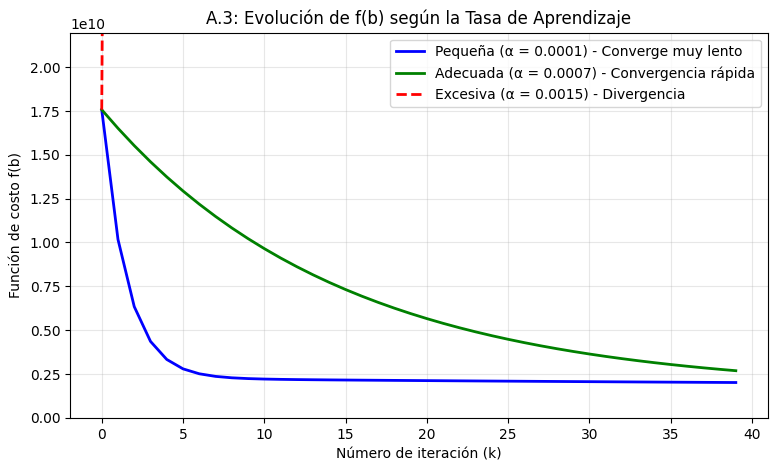


     COMPARACIÓN: DESCENSO DEL GRADIENTE (ADECUADO) VS MCO EXACTO    
Intercepto (β0)        | Gradiente:   3303.3959 | MCO Exacto:   3860.3685 | Dif: 556.9725
β_temp                 | Gradiente:   3584.6384 | MCO Exacto:   2111.8136 | Dif: 1472.8247
β_atemp                | Gradiente:   3620.3500 | MCO Exacto:   5139.1524 | Dif: 1518.8024
β_hum                  | Gradiente:  -2731.7566 | MCO Exacto:  -3149.1098 | Dif: 417.3532
β_windspeed            | Gradiente:  -3050.2941 | MCO Exacto:  -4528.6748 | Dif: 1478.3807


In [ ]:
## A.3 - Descenso del gradiente

# =====================================================================
# SECCIÓN A.3: DESCENSO DEL GRADIENTE Y REGRESIÓN MULTIVARIABLE
# =====================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Carga de seguridad si no existieran variables previas
if 'data' not in globals():
    url = "https://raw.githubusercontent.com/danwild/bike-share-prediction/master/Bike-Sharing-Dataset/day.csv"
    data = pd.read_csv(url)

# 1. Definición de la matriz de diseño X e Y (Variables de B.5)
features = ['temp', 'atemp', 'hum', 'windspeed']
X_mat = np.column_stack([np.ones(len(data)), data[features].values])  # X con columna de 1s para β0
y_vec = data['cnt'].values
n, p = X_mat.shape

# Función de costo: f(b) = Σ (yi - ŷi)²
def loss_func(b, X, y):
    residuos = y - X @ b
    return np.sum(residuos**2)

# Función de gradiente: ∇f(b) = -2 * X.T @ (y - X @ b)
def gradient_func(b, X, y):
    residuos = y - X @ b
    return -2.0 * (X.T @ residuos)

# Algoritmo de descenso del gradiente
def run_gradient_descent(X, y, alpha, max_iters=1500, tol=1e-2):
    b = np.zeros(X.shape[1])  # Punto inicial b(0) = [0, 0, 0, 0, 0]
    hist_loss = [loss_func(b, X, y)]

    for k in range(max_iters):
        grad = gradient_func(b, X, y)
        b_next = b - alpha * grad
        current_loss = loss_func(b_next, X, y)
        hist_loss.append(current_loss)

        # Detección de divergencia
        if np.isnan(current_loss) or current_loss > 1e16:
            break

        # Criterio de detención de la cátedra: |f(b_{k+1}) - f(b_k)| < tol
        if abs(hist_loss[-2] - current_loss) < tol:
            b = b_next
            break

        b = b_next

    return b, hist_loss

# 2. Ejecución con tres tasas de aprendizaje
alpha_small    = 0.0001   # Muy pequeña (convergencia lenta)
alpha_adequate = 0.0007   # Adecuada (convergencia estable)
alpha_diverge  = 0.0015   # Excesiva (provoca divergencia)

print("Ejecutando descenso del gradiente...")
b_small, hist_small = run_gradient_descent(X_mat, y_vec, alpha=alpha_small, max_iters=250)
b_adeq, hist_adeq   = run_gradient_descent(X_mat, y_vec, alpha=alpha_adequate, max_iters=250)
_, hist_div         = run_gradient_descent(X_mat, y_vec, alpha=alpha_diverge, max_iters=20)

# 3. Solución exacta de Mínimos Cuadrados (fórmula B.5: β = (XᵀX)⁻¹ XᵀY)
beta_exacto = np.linalg.inv(X_mat.T @ X_mat) @ (X_mat.T @ y_vec)

# 4. Gráfico comparativo de f en función del número de iteración (mismo par de ejes)
plt.figure(figsize=(9, 5))
iters_plot = 40
plt.plot(range(min(len(hist_small), iters_plot)), hist_small[:iters_plot],
         label=f'Pequeña (α = {alpha_small}) - Converge muy lento', color='blue', lw=2)
plt.plot(range(min(len(hist_adeq), iters_plot)), hist_adeq[:iters_plot],
         label=f'Adecuada (α = {alpha_adequate}) - Convergencia rápida', color='green', lw=2)
plt.plot(range(min(len(hist_div), iters_plot)), hist_div[:iters_plot],
         label=f'Excesiva (α = {alpha_diverge}) - Divergencia', color='red', lw=2, linestyle='--')

plt.xlabel('Número de iteración (k)')
plt.ylabel('Función de costo f(b)')
plt.title('A.3: Evolución de f(b) según la Tasa de Aprendizaje')
plt.ylim(0, hist_small[0] * 1.25)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# 5. Comparación entre la solución obtenida y la exacta de mínimos cuadrados
print("\n" + "="*70)
print("     COMPARACIÓN: DESCENSO DEL GRADIENTE (ADECUADO) VS MCO EXACTO    ")
print("="*70)
nombres = ['Intercepto (β0)'] + [f'β_{col}' for col in features]
for nom, b_g, b_ex in zip(nombres, b_adeq, beta_exacto):
    diff = abs(b_g - b_ex)
    print(f"{nom:22s} | Gradiente: {b_g:11.4f} | MCO Exacto: {b_ex:11.4f} | Dif: {diff:.4f}")
print("="*70)

## Parte B - Complementos de Estadística

In [ ]:
import numpy as np

y = np.array(data['cnt'])
variables = ['temp', 'atemp', 'hum', 'windspeed']
modelos = [RegresionSimple(v, np.array(data[v]), y) for v in variables]

### B.1 - Varianza

Para el modelo de regresión simple de cnt sobre temp, verificar numéricamente la descomposición de la variabilidad y presentarla en una tabla:

In [ ]:
# TODO: ver bien qué tabla hay que armar

sce = modelos[0].sce
scr = modelos[0].scr
stc = sce + scr
stc

np.float64(2739535392.0465117)

In [ ]:
import pandas as pd

# Tomamos el modelo simple de 'temp'
m_temp = modelos[0]
n_obs = len(m_temp)

# Grados de libertad
df_reg = 1
df_res = n_obs - 2
df_tot = n_obs - 1

# Sumas de cuadrados
ss_reg = m_temp.scr
ss_res = m_temp.sce
ss_tot = m_temp.stc

# Cuadrados medios
ms_reg = ss_reg / df_reg
ms_res = ss_res / df_res

# Estadístico F y p-valor
F_stat = ms_reg / ms_res
from scipy.stats import f
p_val = 1 - f.cdf(F_stat, df_reg, df_res)

# Construcción de la tabla ANOVA
anova_data = {
    'Grados de Libertad (gl)': [df_reg, df_res, df_tot],
    'Suma de Cuadrados (SC)': [ss_reg, ss_res, ss_tot],
    'Cuadrados Medios (CM)': [ms_reg, ms_res, None],
    'Estadístico F': [F_stat, None, None],
    'p-valor': [p_val, None, None]
}

tabla_anova = pd.DataFrame(anova_data, index=['Regresión', 'Residuos (Error)', 'Total'])
display(tabla_anova.style.format({
    'Suma de Cuadrados (SC)': '{:,.2f}',
    'Cuadrados Medios (CM)': '{:,.2f}',
    'Estadístico F': '{:.4f}',
    'p-valor': '{:.4e}'
}, na_rep='-'))

,Grados de Libertad (gl),Suma de Cuadrados (SC),Cuadrados Medios (CM),Estadístico F,p-valor
Regresión,1,"1,078,688,585.17","1,078,688,585.17",473.4717,1.1102e-16
Residuos (Error),729,"1,660,846,806.88","2,278,253.51",-,-
Total,730,"2,739,535,392.05",-,-,-


Calcular la estimación de la varianza del modelo:

In [ ]:
modelos[0].sigma2

np.float64(2278253.507375818)

Calcular el coeficiente de determinación e interpretarlo como proporción de variabilidad explicada, indicando explícitamente qué NO significa

In [ ]:
modelos[0].r2

np.float64(0.3937487313729241)

### B.2 - Regresión Lineal Simple

Realizar un análisis de regresión lineal simple entre cnt y cada una de las variables indicadas (temp, atemp, hum, windspeed), y completar el cuadro. Los
intervalos son al 95 % y x* es el valor indicado en B.4 (temperatura normalizada = 0,65).

In [ ]:
tabla = tabular_modelos(modelos)
display(tabla)

,beta1,beta0,sigma2,r2,r,IC(beta1),IC(beta0),IC media(Y|x*=0.65),IC predicción(Y|x*=0.65)
variable,,,,,,,,,
temp,6640.709999,1214.642119,2.278254e+06,0.393749,0.627494,"[5955.2448, 7326.1752]","[898.2421, 1531.0421]","[5387.5973, 5674.6099]","[2564.3640, 8497.8433]"
atemp,7501.833950,945.823981,2.261361e+06,0.398244,0.631066,"[6734.7246, 8268.9433]","[609.5406, 1282.1074]","[5661.4117, 5982.6204]","[2865.3903, 8778.6418]"
hum,-1369.080658,5363.986454,3.719860e+06,0.010132,-0.100659,"[-2494.7765, -243.3848]","[4730.4961, 5997.4768]","[4332.3578, 4615.8102]","[684.9755, 8263.1925]"
windspeed,-5862.912760,5621.152878,3.551207e+06,0.055011,-0.234545,"[-7884.3242, -3841.5014]","[5257.8341, 5984.4717]","[986.9047, 2633.6145]","[-1979.8775, 5600.3967]"


La que mejor correlaciona es `atemp`, con un coeficiente de determinación de 39,82% (bajo). La correlación lineal también es baja, pero es la mayor de las propuestas: 63,1% en proporción directa

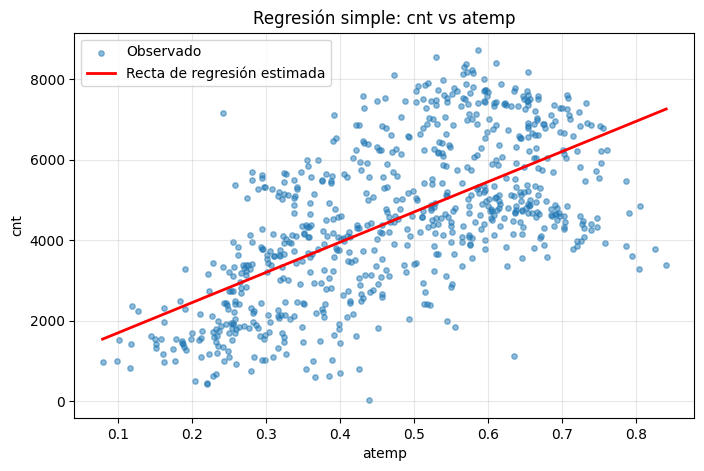

In [ ]:
graficar_modelo(modelos[1], nombre_x='atemp', nombre_y='cnt')

### B.3 - Test de Hipótesis

Se quiere verificar si la variable elegida tiene relación lineal con la cantidad de alquileres.

Se plantean hipótesis nula y alternativa:

\begin{align*}
H_0: \beta_1 = 0 \quad \text{vs.} \quad H_1: \beta_1 \neq 0
\end{align*}

Es decir, en caso de aceptación para H0, implica que `atemp` no tiene relación lineal.

El estadístico de prueba es:

\begin{align*}
T = \frac{\hat{\beta}_1 - 0}{\sqrt{\frac{\hat{\sigma}^2}{S_{xx}}}}
\end{align*}

Obtenemos el valor crítico t(α/2, n-2) para α=0.05:

In [ ]:
from scipy.stats import t

m = modelos[1]
alpha = 0.05
df = len(m) - 2  # grados de libertad

t_critico = t.ppf(1 - alpha / 2, df)
t_critico

np.float64(1.9632234465207086)

Siguiendo la regla de decisión planteada:

\begin{align*}
\text{Rechazar}\space H_0 \space\text{si}\space |T| > t_{\frac{\alpha}{2}, n-2}
\end{align*}

vemos como es |T| respecto al valor crítico obtenido:

In [ ]:
m = modelos[1]
T = m.beta1 / np.sqrt(m.sigma2 / m.sxx)

if abs(T) > t_critico:
    print(f"H0 se rechaza: {abs(T)} = |T| > t(α/2, n-2) = {t_critico}")
else:
    print(f"H0 no se rechaza: {abs(T)} = |T| <= t(α/2, n-2) = {t_critico}")

H0 se rechaza: 21.964842601962577 = |T| > t(α/2, n-2) = 1.9632234465207086


#### Conclusión

Al rechazar H0 estamos diciendo que la pendiente no es nula; esto quiere decir que existe algún grado de relación lineal entre la sensación térmica observada (`atemp`) y la cantidad bicicletas alquiladas (`cnt`).

### B.4 - Intervalos para la respuesta media y predicción

#### Intervalo para la respuesta media

Es un intervalo de confianza para el valor que toma la línea de regresión verdadera cuando x = x*. Dicho valor es fijo, pero desconocido, y se considera que se encuentra dentro del intervalo con un (en este caso) 95% de probabilidad.

In [ ]:
temp = modelos[0]
bottom, top = temp.ic_media(0.65)
print(f'[{bottom}; {top}]')

[5387.597333429889; 5674.609902742142]


#### Intervalo para un valor futuro de Y

Es el intervalo de predicción para los valores factibles de Y. Este intervalo estima el valor de una sola observación futura, considerando el error aleatorio de ese punto alrededor de la media. Por lo tanto, lo que expresa esta predicción es que (en este caso) en un 95% de las veces el valor obtenido caerá dentro del intervalo.

In [ ]:
temp = modelos[0]
bottom, top = temp.ic_prediccion(0.65)
print(f'[{bottom}; {top}]')

[2564.3639585931396; 8497.843277578892]


### B.5 - Regresión Lineal Múltiple

In [ ]:
import numpy as np
import pandas as pd

# 1. Definición de variables y matriz de diseño X e Y
features = ['temp', 'atemp', 'hum', 'windspeed']
X_raw = data[features].values

# Añadimos la columna de unos para incorporar el intercepto beta_0
X = np.column_stack([np.ones(X_raw.shape[0]), X_raw])
Y = data['cnt'].values

# 2. Resolución de las Ecuaciones Normales en forma matricial
# beta = (X^T * X)^(-1) * X^T * Y
XtX = X.T @ X   # @: producto de matrices
XtY = X.T @ Y
beta_matricial = np.linalg.inv(XtX) @ XtY   # linalg.inv(m): inversa de m

# 3. Presentación de resultados
nombres_coef = ['Intercepto (beta0)'] + [f'beta_{col} ({col})' for col in features]

print("===========================================================")
print("    RESOLUCIÓN MATRICIAL DE ECUACIONES NORMALES (B.5)      ")
print("===========================================================")
for nombre, coef in zip(nombres_coef, beta_matricial):
    print(f"{nombre:<25} : {coef:.4f}")
print("-----------------------------------------------------------")

    RESOLUCIÓN MATRICIAL DE ECUACIONES NORMALES (B.5)      
Intercepto (beta0)        : 3860.3685
beta_temp (temp)          : 2111.8136
beta_atemp (atemp)        : 5139.1524
beta_hum (hum)            : -3149.1098
beta_windspeed (windspeed) : -4528.6748
-----------------------------------------------------------


In [ ]:
# 1. Cálculo del R2 para el modelo de regresión múltiple
y_pred_multiple = X @ beta_matricial
sce_multiple = np.sum((Y - y_pred_multiple) ** 2)
stc_multiple = np.sum((Y - Y.mean()) ** 2)
r2_multiple = 1 - (sce_multiple / stc_multiple)

# 2. Cálculo del R2 ajustado para el modelo múltiple
# Fórmula: R2_adj = 1 - [(1 - R2) * (n - 1) / (n - p - 1)]
n = X.shape[0]
p_vars = len(features)  # número de predictores (4)
r2_adj_multiple = 1 - ((1 - r2_multiple) * (n - 1) / (n - p_vars - 1))

# 3. Obtención del R2 del modelo simple (atemp) de la sección B.2
modelo_simple_atemp = modelos[1]  # 'atemp' es el índice 1
r2_simple = modelo_simple_atemp.r2

# 4. Mostrar la comparación
print("===========================================================")
print("       COMPARACIÓN DE COEFICIENTES DE DETERMINACIÓN        ")
print("===========================================================")
print(f"Modelo Simple (atemp) - R²:                     {r2_simple:.4f} ({r2_simple*100:.2f}%)")
print(f"Modelo Múltiple (4 vars) - R²:                 {r2_multiple:.4f} ({r2_multiple*100:.2f}%)")
print(f"Modelo Múltiple (4 vars) - R² Ajustado:        {r2_adj_multiple:.4f} ({r2_adj_multiple*100:.2f}%)")
print("-----------------------------------------------------------")

dif_porcentual = (r2_adj_multiple - r2_simple) * 100
print(f"El modelo múltiple explica un {dif_porcentual:.2f}% más de variabilidad")
print("que el mejor modelo simple, incluso tras penalizar por número de variables.")

       COMPARACIÓN DE COEFICIENTES DE DETERMINACIÓN        
Modelo Simple (atemp) - R²:                     0.3982 (39.82%)
Modelo Múltiple (4 vars) - R²:                 0.4638 (46.38%)
Modelo Múltiple (4 vars) - R² Ajustado:        0.4609 (46.09%)
-----------------------------------------------------------
El modelo múltiple explica un 6.26% más de variabilidad
que el mejor modelo simple, incluso tras penalizar por número de variables.
